# Задача №1. iPhone или Android? Метод k ближайших соседей

**Идея kNN:** для нового человека находим k самых похожих людей из анкеты (по расстоянию между ответами) и смотрим, какой телефон у большинства из них.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_selection import SelectKBest
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Данные

In [2]:
df = pd.read_csv("cool_data.csv")
df.columns = [
    "time", "spotlight", "purchase", "tech", "everyday", "battery", "photo", "design",
    "lags", "apps", "travel", "change_years", "gaming_hours", "posts", "movies",
    "eyes", "metro", "phone",
]
df = df.drop(columns=["time", "eyes", "metro"])
df["phone"].value_counts()

phone
Андроид    28
Айфон      16
Name: count, dtype: int64

In [3]:
X = pd.get_dummies(df.drop(columns="phone"), drop_first=True, dtype=int)
y = df["phone"]
X.head()

,change_years,gaming_hours,spotlight_Комфортно,purchase_Эмоционально,tech_Чтобы всё сразу работало из коробки,everyday_Что-то популярное,battery_Нет,photo_Нет,"design_Долговечность, польза",lags_Нет,apps_Нет,travel_Нет,posts_Нет,movies_Нет
0,4,5,1,0,1,0,0,1,0,1,0,0,1,0
1,3,1,1,0,1,0,0,0,1,1,0,0,0,0
2,3,1,1,0,1,1,1,0,0,1,0,0,1,1
3,3,0,0,0,1,0,0,1,1,1,0,0,1,1
4,4,6,1,0,1,1,0,1,1,0,0,0,1,1


## Подбор k

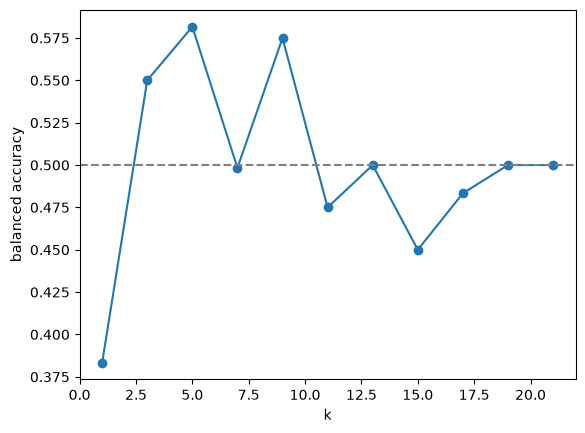

In [4]:
ks = range(1, 22, 2)
scores = []
for k in ks:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores.append(cross_val_score(model, X, y, cv=5, scoring="balanced_accuracy").mean())

plt.plot(ks, scores, marker="o")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("k")
plt.ylabel("balanced accuracy")
plt.show()

Качество около 0.5, то есть почти как угадывание. Попробуем оставить только 4 самых полезных признака.

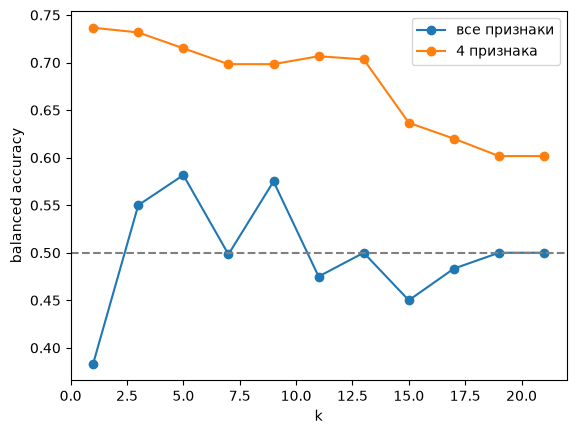

Лучшее k: 1 качество: 0.74


In [5]:
scores_4 = []
for k in ks:
    model = make_pipeline(StandardScaler(), SelectKBest(k=4), KNeighborsClassifier(n_neighbors=k))
    scores_4.append(cross_val_score(model, X, y, cv=5, scoring="balanced_accuracy").mean())

plt.plot(ks, scores, marker="o", label="все признаки")
plt.plot(ks, scores_4, marker="o", label="4 признака")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("k")
plt.ylabel("balanced accuracy")
plt.legend()
plt.show()

best_k = ks[scores_4.index(max(scores_4))]
print("Лучшее k:", best_k, "качество:", round(max(scores_4), 2))

In [14]:
model = make_pipeline(StandardScaler(), SelectKBest(k=4), KNeighborsClassifier(n_neighbors=best_k))
model.fit(X, y)
print("Выбранные признаки:", list(X.columns[model[1].get_support()]))

Выбранные признаки: ['gaming_hours', 'tech_Чтобы всё сразу работало из коробки', 'apps_Нет', 'travel_Нет']


## Прогноз для нового человека

In [15]:
me = X.iloc[[0]].copy()
me[:] = 0
me["gaming_hours"] = 10
me["change_years"] = 4
me["travel_Нет"] = 0
me["tech_Чтобы всё сразу работало из коробки"] = 0
model.predict(me)

array(['Андроид'], dtype=object)

## Выводы

- На всех признаках kNN работает почти как случайное угадывание: большинство вопросов анкеты с телефоном не связаны.
- Если оставить 4 самых полезных признака (часы игр, «из коробки», «приложения работают одинаково», «путешествия»), качество поднимается примерно до 0.7. При k от 1 до 13 разница небольшая, а при большом k качество падает.
- Данных мало (44 ответа), поэтому результат неустойчивый: при другом разбиении на части цифры сдвигаются на 0.1 и больше. Для хорошей модели нужно больше ответов и вопросы, которые ближе к выбору телефона.

## Проверка модели на нормальных данных

In [12]:
phones = pd.read_csv("mobile_price.csv")
phones

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,794,1,0.5,1,0,1,2,0.8,106,6,...,1222,1890,668,13,4,19,1,1,0,0
1996,1965,1,2.6,1,0,0,39,0.2,187,4,...,915,1965,2032,11,10,16,1,1,1,2
1997,1911,0,0.9,1,1,1,36,0.7,108,8,...,868,1632,3057,9,1,5,1,1,0,3
1998,1512,0,0.9,0,4,1,46,0.1,145,5,...,336,670,869,18,10,19,1,1,1,0


In [ ]:
X2 = phones.drop(columns="price_range")
y2 = phones["price_range"]
print(phones.shape)
y2.value_counts()

(2000, 21)


price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

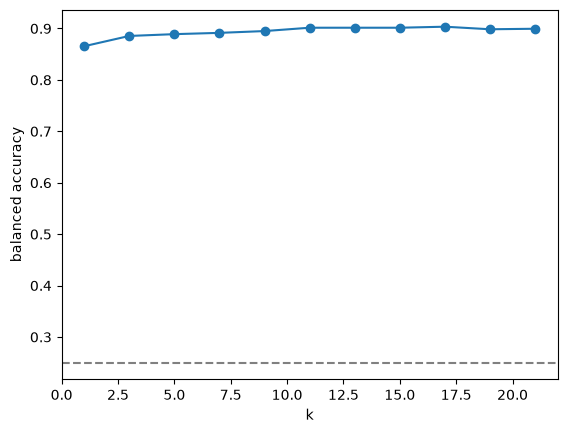

Лучшее k: 17 качество: 0.9


In [9]:
scores_2 = []
for k in ks:
    model = make_pipeline(StandardScaler(), SelectKBest(k=4), KNeighborsClassifier(n_neighbors=k))
    scores_2.append(cross_val_score(model, X2, y2, cv=5, scoring="balanced_accuracy").mean())

plt.plot(ks, scores_2, marker="o")
plt.axhline(0.25, color="gray", linestyle="--")
plt.xlabel("k")
plt.ylabel("balanced accuracy")
plt.show()

best_k2 = ks[scores_2.index(max(scores_2))]
print("Лучшее k:", best_k2, "качество:", round(max(scores_2), 2))

In [ ]:
model2 = make_pipeline(StandardScaler(), SelectKBest(k=4), KNeighborsClassifier(n_neighbors=best_k2))
model2.fit(X2, y2)
print("Выбранные признаки:", list(X2.columns[model2[1].get_support()]))

Выбранные признаки: ['battery_power', 'px_height', 'px_width', 'ram']
